# Assignment 2 - Explainable AI on Brain-Tumour MRI
**Layer-wise Relevance Propagation (LRP) + Grad-CAM** on a VGG16 tumour classifier.

This notebook is built on `05_lrp.py` from *deepfindr/xai-series*. The model,
data pipeline and LRP rules follow the original; every deviation is marked
`# CHANGED:` with the reason. Dataset: *SartajBhuvaji/Brain-Tumor-Classification-DataSet*,
4 classes (glioma, meningioma, no tumour, pituitary), stored in `data/brain_mri/{training,testing}`.

Contents
1. Data & model (VGG16, transfer learning)
2. Training and evaluation (accuracy, confusion matrix, calibration, MC-dropout uncertainty)
3. XAI method 1 - LRP (gamma / epsilon / 0 rules + z^B rule for the pixel layer)
4. XAI method 2 - Grad-CAM
5. LRP vs Grad-CAM + quantitative explanation metrics (bonus)
6. Error analysis - false negatives / false positives (bonus)

**Running on Google Colab:** Runtime -> Change runtime type -> **T4 GPU**, then
Runtime -> **Run all**. The first cells download the dataset and xai-series from GitHub
(Tasks 1-2); the last cell downloads `brain_xai_outputs.zip` (figures + results).
Afterwards use File -> Download -> Download .ipynb to keep this notebook with its outputs.

In [1]:
import copy
import json
import os
import random
import shutil
import subprocess
import sys
import time
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.models as models
import torchvision.transforms as transforms
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Subset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

In [2]:
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    os.chdir("/content")
    for repo in ["https://github.com/SartajBhuvaji/Brain-Tumor-Classification-DataSet.git",
                 "https://github.com/deepfindr/xai-series.git"]:
        folder = repo.rsplit("/", 1)[-1].removesuffix(".git")
        if not Path(folder).exists():
            subprocess.run(["git", "clone", "--depth", "1", repo], check=True)
    for source, target in [("Training", "training"), ("Testing", "testing")]:
        destination = Path("xai-series/data/brain_mri") / target
        if not destination.exists():
            shutil.copytree(Path("Brain-Tumor-Classification-DataSet") / source, destination)
    os.chdir("/content/xai-series")
    for split in ("training", "testing"):
        for class_dir in sorted(Path("data/brain_mri", split).iterdir()):
            print(f"{split:9s} {class_dir.name:17s} {len(list(class_dir.iterdir())):4d} images")

training  glioma_tumor       826 images
training  meningioma_tumor   822 images
training  no_tumor           395 images
training  pituitary_tumor    827 images
testing   glioma_tumor       100 images
testing   meningioma_tumor   115 images
testing   no_tumor           105 images
testing   pituitary_tumor     74 images


In [3]:
# CHANGED: the original hard-codes "cuda:0"; fall back to the CPU when there is no GPU.
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
if IN_COLAB and device.type != "cuda":
    raise RuntimeError("No GPU found. In Colab: Runtime -> Change runtime type -> T4 GPU, then Run all again.")
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
torch.set_num_threads(os.cpu_count() or 4)
print("Device:", device, "| torch", torch.__version__, "| torchvision", torchvision.__version__)

# QUICK=1 runs a tiny smoke test (few images, 1 epoch) to check the pipeline end-to-end.
QUICK = os.environ.get("QUICK") == "1"

TRAIN_ROOT = "data/brain_mri/training"
TEST_ROOT = "data/brain_mri/testing"
FIG_DIR = Path("figures_quick" if QUICK else "figures")
RESULTS_DIR = Path("results_quick" if QUICK else "results")
MODEL_PATH = Path("models") / ("vgg16_brain_mri_quick.pt" if QUICK else "vgg16_brain_mri.pt")
for d in (FIG_DIR, RESULTS_DIR, MODEL_PATH.parent):
    d.mkdir(exist_ok=True)

IMG_SIZE = 224
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

GPU: Tesla T4
Device: cuda:0 | torch 2.14.1+cu130 | torchvision 0.29.1+cu130


In [4]:
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
BLUE, ORANGE, AQUA, YELLOW, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#9a9993"
RED = "#e34948"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "text.color": INK, "axes.titlecolor": INK, "axes.grid": False, "grid.color": GRID,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
    "axes.titlesize": 10, "figure.titlesize": 12, "figure.dpi": 110, "savefig.dpi": 150,
})
# Diverging map for signed LRP relevance: blue = evidence against, gray = neutral, red = evidence for.
LRP_CMAP = LinearSegmentedColormap.from_list("lrp_div", [BLUE, "#f0efec", RED])


def save(fig, name):
    fig.savefig(FIG_DIR / name, bbox_inches="tight")
    plt.show()
    plt.close(fig)

In [5]:
# CHANGED: ImageNet normalisation added - the VGG16 weights were trained on normalised
# inputs, and the z^B pixel rule of LRP needs the known input bounds this gives us.
# CHANGED: 224x224 (VGG's native size) instead of 255x255, so the last feature map is
# exactly 7x7 and the dense->conv conversion used by LRP is exact.
# CHANGED: the original accidentally built the first test_dataset from TRAIN_ROOT.
preprocess = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
train_full = torchvision.datasets.ImageFolder(root=TRAIN_ROOT, transform=preprocess)
test_dataset = torchvision.datasets.ImageFolder(root=TEST_ROOT, transform=preprocess)
CLASSES = train_full.classes
PRETTY = {"glioma_tumor": "Glioma", "meningioma_tumor": "Meningioma",
          "no_tumor": "No tumour", "pituitary_tumor": "Pituitary"}
NAMES = [PRETTY[c] for c in CLASSES]
NO_TUMOR = CLASSES.index("no_tumor")
assert train_full.class_to_idx == test_dataset.class_to_idx

# CHANGED: hold out 10% of the training set (stratified) for model selection, so the
# test set is used only once, for the final report.
train_labels = np.array(train_full.targets)
train_idx, val_idx = train_test_split(np.arange(len(train_full)), test_size=0.10,
                                      stratify=train_labels, random_state=SEED)
test_idx = np.arange(len(test_dataset))
if QUICK:
    train_idx, val_idx = train_idx[::40], val_idx[::20]
    test_idx = np.concatenate([np.where(np.array(test_dataset.targets) == c)[0][:6] for c in range(4)])

counts = pd.DataFrame({
    "train": np.bincount(train_labels[train_idx], minlength=4),
    "val": np.bincount(train_labels[val_idx], minlength=4),
    "test": np.bincount(np.array(test_dataset.targets)[test_idx], minlength=4),
}, index=NAMES)
print(counts)


def to_display(img_tensor):
    """Undo ImageNet normalisation -> HxWx3 float image in [0, 1]."""
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    return (img_tensor.cpu() * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()


def to_gray_uint8(img_tensor):
    return (to_display(img_tensor).mean(axis=2) * 255).astype(np.uint8)

            train  val  test
Glioma        743   83   100
Meningioma    740   82   115
No tumour     356   39   105
Pituitary     744   83    74


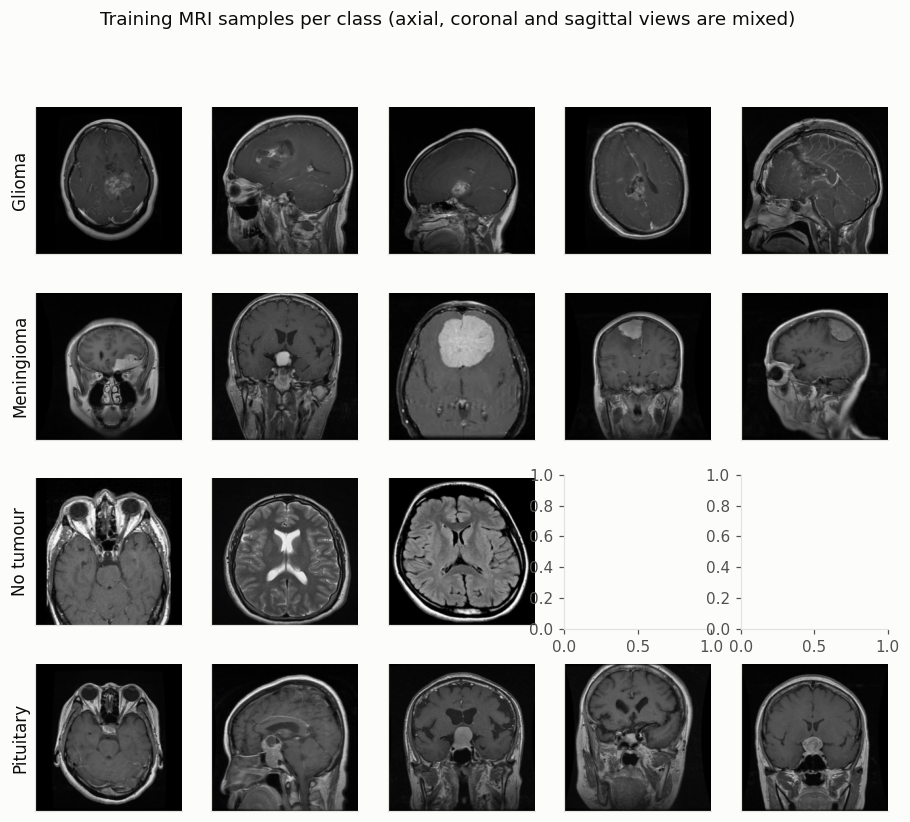

In [6]:
fig, axes = plt.subplots(4, 5, figsize=(10, 8.4))
for c in range(4):
    paths = [i for i, t in enumerate(train_full.targets) if t == c][:: 150][:5]
    for j, i in enumerate(paths):
        ax = axes[c, j]
        ax.imshow(to_display(train_full[i][0]))
        ax.set_xticks([]); ax.set_yticks([])
        if j == 0:
            ax.set_ylabel(NAMES[c], fontsize=11, color=INK)
fig.suptitle("Training MRI samples per class (axial, coronal and sagittal views are mixed)")
save(fig, "01_dataset_samples.png")

In [7]:
class CNNModel(nn.Module):
    def __init__(self):
        super(CNNModel, self).__init__()
        # CHANGED: `pretrained=True` is deprecated in torchvision >= 0.13.
        self.vgg16 = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1)

        # Replace output layer according to our problem
        in_feats = self.vgg16.classifier[6].in_features
        self.vgg16.classifier[6] = nn.Linear(in_feats, 4)

    def forward(self, x):
        x = self.vgg16(x)
        return x


model = CNNModel()
model.to(device)

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:06<00:00, 86.6MB/s]


CNNModel(
  (vgg16): VGG(
    (features): Sequential(
      (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (3): ReLU(inplace=True)
      (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (6): ReLU(inplace=True)
      (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (8): ReLU(inplace=True)
      (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (11): ReLU(inplace=True)
      (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (13): ReLU(inplace=True)
      (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (15): ReLU(inplace=True)
      (16):

In [8]:
# GPU (e.g. Colab T4): fine-tune ALL layers, exactly like the original 05_lrp.py
# (Adam, lr 1e-5, 10 epochs, batch 32), with random horizontal flips as augmentation.
# CHANGED (CPU fallback only): full fine-tuning takes many hours on a CPU, so there the
# ImageNet feature extractor up to conv5_2 stays frozen and only conv5_3 + the classifier
# are trained, on cached frozen features. Either way the architecture is unchanged, so
# LRP and Grad-CAM run on the full VGG16.
# FORCE_FULL=1 exercises the full fine-tuning path on a CPU (testing only - very slow on full data).
FULL_FINETUNE = device.type == "cuda" or os.environ.get("FORCE_FULL") == "1"
FREEZE_UNTIL = 28          # CPU fallback: features[28] = conv5_3 is the first trainable layer
EPOCHS = 1 if QUICK else 10
BATCH_SIZE = 8 if QUICK else 32
LEARNING_RATE = 1e-5 if FULL_FINETUNE else 5e-5
USE_AMP = device.type == "cuda"  # mixed precision: ~2x faster on the T4; LRP itself runs in fp32

if FULL_FINETUNE:
    for p in model.parameters():
        p.requires_grad = True
    TRAINABLE_PREFIXES = ("vgg16.",)
else:
    for p in model.parameters():
        p.requires_grad = False
    for module in (model.vgg16.features[FREEZE_UNTIL], model.vgg16.classifier):
        for p in module.parameters():
            p.requires_grad = True
    TRAINABLE_PREFIXES = (f"vgg16.features.{FREEZE_UNTIL}.", "vgg16.classifier.")
print("Strategy:", "full fine-tuning (all layers)" if FULL_FINETUNE else "partial fine-tuning (conv5_3 + classifier, cached features)")
n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable parameters: {n_trainable/1e6:.1f}M of {sum(p.numel() for p in model.parameters())/1e6:.1f}M")


def trunk_forward(x):
    return model.vgg16.features[:FREEZE_UNTIL](x)


def head_forward(h):
    h = model.vgg16.features[FREEZE_UNTIL:](h)
    h = model.vgg16.avgpool(h)
    return model.vgg16.classifier(torch.flatten(h, 1))


@torch.no_grad()
def cache_trunk_features(dataset, indices, flip=False):
    loader = DataLoader(Subset(dataset, indices), batch_size=32, shuffle=False, num_workers=0)
    feats, labels = [], []
    for x, y in loader:
        if flip:
            x = torch.flip(x, dims=[3])
        feats.append(trunk_forward(x.to(device)).half().cpu())  # fp16 halves RAM use
        labels.append(y)
    return torch.cat(feats), torch.cat(labels)


def train_model(epoch_batches, val_batches, forward):
    """Shared training loop. epoch_batches() / val_batches() yield (inputs, labels) for one pass."""
    # CHANGED: class-weighted loss - "no tumour" has half as many training images, and
    # missing that class drives false positives (healthy patients flagged as tumour).
    class_counts = np.bincount(train_labels[train_idx], minlength=4)
    class_weights = torch.tensor(class_counts.sum() / (4 * class_counts), dtype=torch.float32, device=device)
    cross_entropy_loss = nn.CrossEntropyLoss(weight=class_weights)
    optimizer = optim.Adam([p for p in model.parameters() if p.requires_grad], lr=LEARNING_RATE)
    scaler = torch.amp.GradScaler(device.type, enabled=USE_AMP)

    history, best_val_acc, best_state = [], -1.0, None
    for epoch in range(EPOCHS):
        model.train()  # turns on dropout in the classifier
        running_loss, running_correct, seen = 0.0, 0, 0
        t0 = time.time()
        for inputs, labels in epoch_batches():
            inputs, labels = inputs.to(device, non_blocking=True), labels.to(device, non_blocking=True)
            optimizer.zero_grad()
            with torch.autocast(device.type, dtype=torch.float16, enabled=USE_AMP):
                outputs = forward(inputs)
            loss = cross_entropy_loss(outputs.float(), labels)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            running_loss += loss.item() * len(labels)
            running_correct += (outputs.argmax(1) == labels).sum().item()
            seen += len(labels)

        model.eval()
        val_out, val_y = [], []
        with torch.no_grad(), torch.autocast(device.type, dtype=torch.float16, enabled=USE_AMP):
            for inputs, labels in val_batches():
                val_out.append(forward(inputs.to(device)).float().cpu())
                val_y.append(labels)
        val_out, val_y = torch.cat(val_out), torch.cat(val_y)
        val_acc = (val_out.argmax(1) == val_y).float().mean().item()
        record = {"epoch": epoch + 1, "train_loss": running_loss / seen, "train_acc": running_correct / seen,
                  "val_loss": F.cross_entropy(val_out, val_y).item(), "val_acc": val_acc}
        history.append(record)
        print(f"epoch {epoch+1:2d} | loss {record['train_loss']:.3f} | train acc {record['train_acc']:.3f}"
              f" | val loss {record['val_loss']:.3f} | val acc {val_acc:.3f} | {time.time()-t0:.0f}s")
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()
                          if k.startswith(TRAINABLE_PREFIXES)}
    return history, best_state

Strategy: full fine-tuning (all layers)
Trainable parameters: 134.3M of 134.3M


In [9]:
history_path = RESULTS_DIR / "training_history.json"
if MODEL_PATH.exists():
    model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
    history = json.loads(history_path.read_text())
    print("Loaded trained model from", MODEL_PATH)
else:
    if FULL_FINETUNE:
        train_augmented = torchvision.datasets.ImageFolder(root=TRAIN_ROOT, transform=transforms.Compose([
            transforms.Resize((IMG_SIZE, IMG_SIZE)),
            transforms.RandomHorizontalFlip(),
            transforms.ToTensor(),
            transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
        ]))
        # Worker processes only on Linux/Colab: on Windows they re-import this whole script.
        loader_kwargs = dict(batch_size=BATCH_SIZE, num_workers=2 if IN_COLAB else 0, pin_memory=device.type == "cuda")
        train_loader = DataLoader(Subset(train_augmented, train_idx), shuffle=True, **loader_kwargs)
        val_loader = DataLoader(Subset(train_full, val_idx), shuffle=False, **loader_kwargs)
        history, best_state = train_model(lambda: train_loader, lambda: val_loader, model)
    else:
        model.eval()
        t0 = time.time()
        X_train, y_train = cache_trunk_features(train_full, train_idx)
        X_train_flip, _ = cache_trunk_features(train_full, train_idx, flip=True)
        X_val, y_val = cache_trunk_features(train_full, val_idx)
        print(f"Cached frozen features in {time.time()-t0:.0f}s: {tuple(X_train.shape)}")

        def cached_train_batches():
            perm = torch.randperm(len(X_train))
            for b in range(0, len(perm), BATCH_SIZE):
                idx = perm[b:b + BATCH_SIZE]
                use_flip = (torch.rand(len(idx)) < 0.5).view(-1, 1, 1, 1)
                yield torch.where(use_flip, X_train_flip[idx], X_train[idx]).float(), y_train[idx]

        def cached_val_batches():
            for b in range(0, len(X_val), 64):
                yield X_val[b:b + 64].float(), y_val[b:b + 64]

        history, best_state = train_model(cached_train_batches, cached_val_batches, head_forward)
        del X_train, X_train_flip, X_val

    model.load_state_dict(best_state, strict=False)  # keep the epoch with best validation accuracy
    torch.save(model.state_dict(), MODEL_PATH)
    history_path.write_text(json.dumps(history, indent=2))

model.eval()
for p in model.parameters():
    p.requires_grad = False

epoch  1 | loss 0.910 | train acc 0.618 | val loss 0.412 | val acc 0.864 | 27s
epoch  2 | loss 0.386 | train acc 0.844 | val loss 0.315 | val acc 0.885 | 26s
epoch  3 | loss 0.266 | train acc 0.891 | val loss 0.212 | val acc 0.927 | 26s
epoch  4 | loss 0.190 | train acc 0.920 | val loss 0.210 | val acc 0.927 | 25s
epoch  5 | loss 0.142 | train acc 0.947 | val loss 0.146 | val acc 0.948 | 26s
epoch  6 | loss 0.094 | train acc 0.964 | val loss 0.148 | val acc 0.937 | 26s
epoch  7 | loss 0.069 | train acc 0.977 | val loss 0.170 | val acc 0.934 | 26s
epoch  8 | loss 0.060 | train acc 0.977 | val loss 0.143 | val acc 0.944 | 26s
epoch  9 | loss 0.036 | train acc 0.986 | val loss 0.144 | val acc 0.944 | 26s
epoch 10 | loss 0.032 | train acc 0.988 | val loss 0.154 | val acc 0.948 | 26s


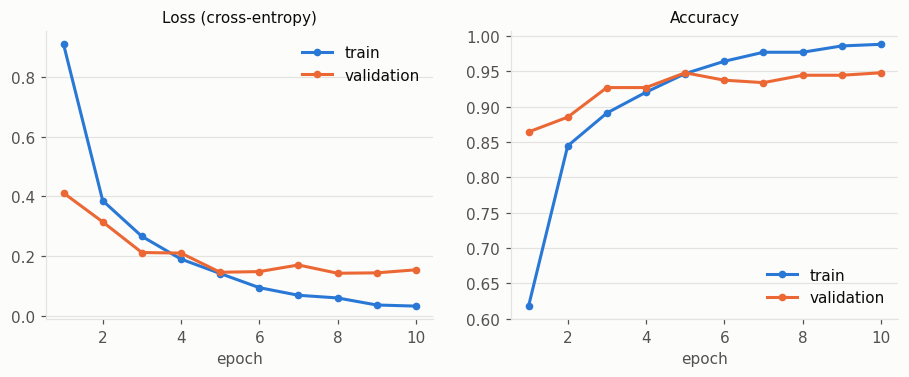

In [10]:
hist = pd.DataFrame(history)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, metric, title in [(axes[0], "loss", "Loss (cross-entropy)"), (axes[1], "acc", "Accuracy")]:
    ax.plot(hist.epoch, hist[f"train_{metric}"], color=BLUE, lw=2, marker="o", ms=4, label="train")
    ax.plot(hist.epoch, hist[f"val_{metric}"], color=ORANGE, lw=2, marker="o", ms=4, label="validation")
    ax.set_title(title); ax.set_xlabel("epoch"); ax.grid(axis="y")
    ax.legend(frameon=False)
save(fig, "02_training_curves.png")

Test accuracy: 0.751  (296/394)
              precision    recall  f1-score   support

      Glioma      1.000     0.310     0.473       100
  Meningioma      0.660     0.913     0.766       115
   No tumour      0.705     1.000     0.827       105
   Pituitary      1.000     0.743     0.853        74

    accuracy                          0.751       394
   macro avg      0.841     0.742     0.730       394
weighted avg      0.822     0.751     0.724       394

Tumour-vs-healthy sensitivity 0.848 | specificity 1.000


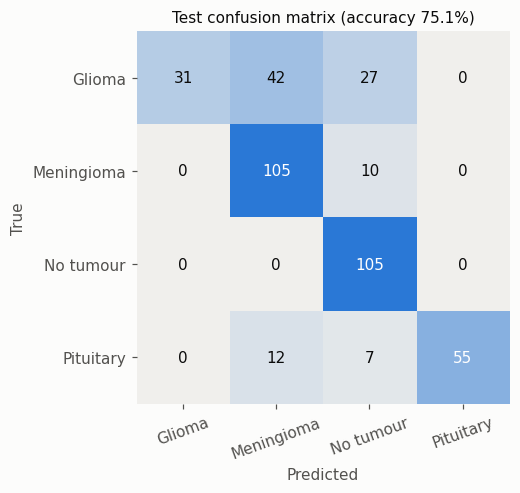

In [11]:
@torch.no_grad()
def predict(dataset, indices):
    loader = DataLoader(Subset(dataset, indices), batch_size=32, shuffle=False, num_workers=0)
    logits, labels, embeddings = [], [], []
    for x, y in loader:
        h = torch.flatten(model.vgg16.avgpool(model.vgg16.features(x.to(device))), 1)
        logits.append(model.vgg16.classifier(h).cpu())
        embeddings.append(h.cpu())
        labels.append(y)
    return torch.cat(logits), torch.cat(labels).numpy(), torch.cat(embeddings)


test_logits, y_true, test_embeddings = predict(test_dataset, test_idx)
test_probs = F.softmax(test_logits, 1).numpy()
y_pred = test_probs.argmax(1)
test_acc = float((y_pred == y_true).mean())
print(f"Test accuracy: {test_acc:.3f}  ({(y_pred == y_true).sum()}/{len(y_true)})")
report = classification_report(y_true, y_pred, labels=range(4), target_names=NAMES, output_dict=True, zero_division=0)
print(classification_report(y_true, y_pred, labels=range(4), target_names=NAMES, digits=3, zero_division=0))

# Clinically the most important binary question: tumour vs no tumour.
is_tumor_true, is_tumor_pred = y_true != NO_TUMOR, y_pred != NO_TUMOR
tumor_sensitivity = float((is_tumor_pred & is_tumor_true).sum() / is_tumor_true.sum())
tumor_specificity = float((~is_tumor_pred & ~is_tumor_true).sum() / max((~is_tumor_true).sum(), 1))
print(f"Tumour-vs-healthy sensitivity {tumor_sensitivity:.3f} | specificity {tumor_specificity:.3f}")

cm = confusion_matrix(y_true, y_pred, labels=range(4))
fig, ax = plt.subplots(figsize=(5.2, 4.4))
ax.imshow(cm, cmap=LinearSegmentedColormap.from_list("seq", ["#f0efec", BLUE]))
for i in range(4):
    for j in range(4):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else INK)
ax.set_xticks(range(4), NAMES, rotation=20); ax.set_yticks(range(4), NAMES)
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
ax.set_title(f"Test confusion matrix (accuracy {test_acc:.1%})")
for s in ax.spines.values():
    s.set_visible(False)
save(fig, "03_confusion_matrix.png")

ECE 0.147 | mean normalised entropy: correct 0.230, wrong 0.399


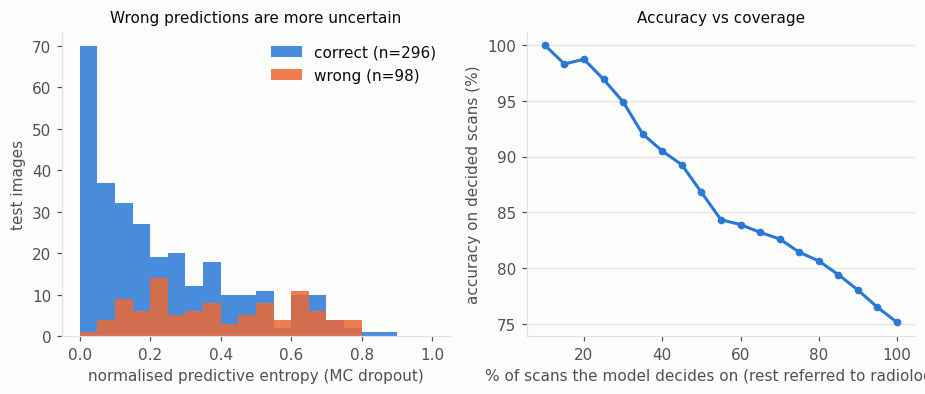

In [12]:
def expected_calibration_error(probs, labels, n_bins=10):
    conf, pred = probs.max(1), probs.argmax(1)
    bins = np.linspace(0, 1, n_bins + 1)
    ece = 0.0
    for lo, hi in zip(bins[:-1], bins[1:]):
        in_bin = (conf > lo) & (conf <= hi)
        if in_bin.any():
            ece += in_bin.mean() * abs((pred[in_bin] == labels[in_bin]).mean() - conf[in_bin].mean())
    return float(ece)


@torch.no_grad()
def mc_dropout_probs(embeddings, passes=30):
    """Keep the classifier's dropout ON at test time: the spread of predictions approximates model uncertainty."""
    model.vgg16.classifier.train()
    probs = torch.stack([F.softmax(model.vgg16.classifier(embeddings.to(device)), 1).cpu()
                         for _ in range(passes)])
    model.vgg16.classifier.eval()
    return probs.numpy()  # (passes, N, 4)


ece = expected_calibration_error(test_probs, y_true)
mc_probs = mc_dropout_probs(test_embeddings)
mc_mean = mc_probs.mean(0)
predictive_entropy = -(mc_mean * np.log(mc_mean + 1e-12)).sum(1) / np.log(4)  # 0 = certain, 1 = max
correct = y_pred == y_true
print(f"ECE {ece:.3f} | mean normalised entropy: correct {predictive_entropy[correct].mean():.3f}, "
      f"wrong {predictive_entropy[~correct].mean() if (~correct).any() else float('nan'):.3f}")

# Selective prediction: if the most uncertain cases are referred to a radiologist, how accurate is the rest?
order = np.argsort(predictive_entropy)
coverages = np.linspace(0.1, 1.0, 19)
selective_acc = [float(correct[order[:max(1, int(round(c * len(order))))]].mean()) for c in coverages]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
bins = np.linspace(0, 1, 21)
axes[0].hist(predictive_entropy[correct], bins=bins, color=BLUE, alpha=0.85, label=f"correct (n={correct.sum()})")
axes[0].hist(predictive_entropy[~correct], bins=bins, color=ORANGE, alpha=0.85, label=f"wrong (n={(~correct).sum()})")
axes[0].set_xlabel("normalised predictive entropy (MC dropout)"); axes[0].set_ylabel("test images")
axes[0].set_title("Wrong predictions are more uncertain"); axes[0].legend(frameon=False)
axes[1].plot(coverages * 100, np.array(selective_acc) * 100, color=BLUE, lw=2, marker="o", ms=4)
axes[1].set_xlabel("% of scans the model decides on (rest referred to radiologist)")
axes[1].set_ylabel("accuracy on decided scans (%)"); axes[1].grid(axis="y")
axes[1].set_title("Accuracy vs coverage")
save(fig, "04_uncertainty.png")

## XAI method 1 - Layer-wise Relevance Propagation (LRP)
LRP redistributes the class score backwards through the network, layer by layer, so that
(approximately) the relevance assigned to the pixels sums to the score. Rules as in the
original (Montavon et al., 2019):
* lower layers (conv1-conv3): **LRP-gamma** - favours positive evidence, gives stable maps
* middle layers (conv4-conv5): **LRP-epsilon** - absorbs weak / contradictory contributions
* classifier layers: **LRP-0**
* **CHANGED:** pixel layer uses the **z^B rule** (the "Potential Step 5" left open in the original),
  which is the correct rule for bounded pixel inputs.

Red = pixels that pushed the model *towards* the predicted class, blue = *against* it.

In [13]:
# Source: https://git.tu-berlin.de/gmontavon/lrp-tutorial
# http://iphome.hhi.de/samek/pdf/MonXAI19.pdf


def new_layer(layer, g):
    """Clone a layer and pass its parameters through the function g."""
    layer = copy.deepcopy(layer)
    try: layer.weight = torch.nn.Parameter(g(layer.weight))
    except AttributeError: pass
    try: layer.bias = torch.nn.Parameter(g(layer.bias))
    except AttributeError: pass
    return layer


def dense_to_conv(layers):
    """ Converts a dense layer to a conv layer """
    newlayers = []
    for i, layer in enumerate(layers):
        if isinstance(layer, nn.Linear):
            newlayer = None
            if i == 0:
                m, n = 512, layer.weight.shape[0]
                newlayer = nn.Conv2d(m, n, 7)
                newlayer.weight = nn.Parameter(layer.weight.reshape(n, m, 7, 7))
            else:
                m, n = layer.weight.shape[1], layer.weight.shape[0]
                newlayer = nn.Conv2d(m, n, 1)
                newlayer.weight = nn.Parameter(layer.weight.reshape(n, m, 1, 1))
            newlayer.bias = nn.Parameter(layer.bias)
            newlayers += [newlayer]
        else:
            newlayers += [layer]
    return newlayers


# CHANGED: build the layer list once (the original rebuilt it per image) and keep the
# classifier in conv form throughout, which removes the flatten/reshape special case.
LRP_LAYERS = list(model.vgg16.features) + [model.vgg16.avgpool] + dense_to_conv(list(model.vgg16.classifier))
for layer in LRP_LAYERS:
    layer.eval()
    for p in layer.parameters():
        p.requires_grad = False


def stabilize(z, eps):
    """Sign-aware stabiliser: push z AWAY from zero, never across it.
    CHANGED: the original adds +eps regardless of sign, so a slightly negative z ends up
    next to zero; dividing by it explodes and, over many layers, overflows to inf/NaN
    (this happened for ~half of the test images with the fully fine-tuned model)."""
    return z + eps * torch.where(z >= 0, 1.0, -1.0)


def lrp_rule(layer_index):
    # Lower layers, LRP-gamma >> Favor positive contributions (activations)
    if layer_index <= 16:
        return (lambda p: p + 0.25 * p.clamp(min=0)), (lambda z: stabilize(z, 1e-9))
    # Middle layers, LRP-epsilon >> Remove some noise / Only most salient factors survive
    if layer_index <= 30:
        return (lambda p: p), (lambda z: stabilize(z, 1e-9 + 0.25 * ((z ** 2).mean() ** .5).data))
    # Upper Layers, LRP-0 >> Basic rule
    return (lambda p: p), (lambda z: stabilize(z, 1e-9))


def apply_lrp_on_vgg16(image, target=None):
    """Returns (pixel relevance HxW, explained class, class logit) for one normalised image."""
    layers = list(LRP_LAYERS)
    n_layers = len(layers)
    # >>> Step 1/2: propagate the image through the layers and store activations
    activations = [image.unsqueeze(0).to(device)] + [None] * n_layers
    with torch.no_grad():
        for i in range(n_layers):
            activations[i + 1] = layers[i](activations[i])

    # >>> Step 3: keep only the explained class's score (one-hot mask)
    # CHANGED: the original masks by `val == max`, which always explains the argmax and
    # can tie; an explicit target lets us also ask "why NOT the true class?".
    logits = activations[-1].reshape(-1)
    target = int(logits.argmax()) if target is None else int(target)
    mask = torch.zeros_like(logits)
    mask[target] = 1.0
    relevances = [None] * n_layers + [activations[-1] * mask.view(1, -1, 1, 1)]

    # >>> Step 4: backpropagate relevance scores (all layers except the pixel layer)
    with torch.enable_grad():
        for i in range(1, n_layers)[::-1]:
            current = layers[i]
            # Treat max pooling layers as avg pooling
            if isinstance(current, nn.MaxPool2d):
                current = nn.AvgPool2d(2)
            if isinstance(current, (nn.Conv2d, nn.AvgPool2d)):
                a = activations[i].data.requires_grad_(True)
                rho, incr = lrp_rule(i)
                # Transform weights of layer and execute forward pass
                z = incr(new_layer(current, rho).forward(a))
                # Element-wise division between relevance of the next layer and z
                s = (relevances[i + 1] / z).data
                # Calculate the gradient and multiply it by the activation
                (z * s).sum().backward()
                relevances[i] = (a * a.grad).data
            else:
                relevances[i] = relevances[i + 1]

        # >>> Step 5 (CHANGED - implemented): z^B rule for the pixel layer.
        # Pixels are bounded between the normalised values of black (lb) and white (hb).
        x = activations[0].data.requires_grad_(True)
        mean = torch.tensor(IMAGENET_MEAN, device=device).view(1, 3, 1, 1)
        std = torch.tensor(IMAGENET_STD, device=device).view(1, 3, 1, 1)
        lb = ((0 - mean) / std).expand_as(x).clone().requires_grad_(True)
        hb = ((1 - mean) / std).expand_as(x).clone().requires_grad_(True)
        first = layers[0]
        z = first.forward(x)
        z = z - new_layer(first, lambda p: p.clamp(min=0)).forward(lb)
        z = z - new_layer(first, lambda p: p.clamp(max=0)).forward(hb)
        z = stabilize(z, 1e-9)
        s = (relevances[1] / z).data
        (z * s).sum().backward()
        relevances[0] = (x * x.grad + lb * lb.grad + hb * hb.grad).data

    # CHANGED: sum relevance over the RGB channels (the original plotted channel 0 only).
    pixel_relevance = relevances[0][0].sum(0).cpu().numpy()
    return pixel_relevance, target, float(logits[target])

In [14]:
GRADCAM_LAYER = 29  # ReLU after conv5_3: last conv layer, 14x14 spatial grid


def grad_cam(image, target=None):
    """Grad-CAM (Selvaraju et al., 2017) on conv5_3. Returns (heatmap 224x224 in [0,1], 14x14 grid, class)."""
    with torch.enable_grad():
        x = image.unsqueeze(0).to(device)
        with torch.no_grad():
            feature_map = model.vgg16.features[:GRADCAM_LAYER + 1](x)
        feature_map = feature_map.detach().requires_grad_(True)
        h = model.vgg16.avgpool(model.vgg16.features[GRADCAM_LAYER + 1:](feature_map))
        logits = model.vgg16.classifier(torch.flatten(h, 1))[0]
        target = int(logits.argmax()) if target is None else int(target)
        logits[target].backward()
    channel_weights = feature_map.grad.mean(dim=(2, 3), keepdim=True)      # global-average gradients
    cam = F.relu((channel_weights * feature_map).sum(1, keepdim=True))       # weighted sum of maps
    grid = cam[0, 0].detach().cpu().numpy()
    cam = F.interpolate(cam, size=(IMG_SIZE, IMG_SIZE), mode="bilinear", align_corners=False)[0, 0]
    cam = cam.detach().cpu().numpy()
    return cam / (cam.max() + 1e-12), grid / (grid.max() + 1e-12), target

In [15]:
def head_mask(gray_uint8):
    """Rough head/brain mask: Otsu threshold -> close holes -> keep largest blob, filled."""
    blur = cv2.GaussianBlur(gray_uint8, (5, 5), 0)
    _, th = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    th = cv2.morphologyEx(th, cv2.MORPH_CLOSE, np.ones((9, 9), np.uint8))
    contours, _ = cv2.findContours(th, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    mask = np.zeros_like(gray_uint8)
    if contours:
        cv2.drawContours(mask, [max(contours, key=cv2.contourArea)], -1, 255, thickness=cv2.FILLED)
    return mask > 0


def show_lrp(ax, relevance):
    limit = np.percentile(np.abs(relevance), 99.5) + 1e-12
    ax.imshow(relevance, cmap=LRP_CMAP, vmin=-limit, vmax=limit)
    ax.set_xticks([]); ax.set_yticks([])


def overlay(ax, gray, heat, color, alpha_max=0.65):
    """Single-hue overlay: opacity grows with explanation strength, so the anatomy stays visible."""
    ax.imshow(gray, cmap="gray")
    rgba = np.zeros(heat.shape + (4,))
    rgba[..., :3] = matplotlib_rgb(color)
    rgba[..., 3] = alpha_max * np.clip(heat, 0, 1)
    ax.imshow(rgba)
    ax.set_xticks([]); ax.set_yticks([])


def matplotlib_rgb(hex_color):
    return np.array([int(hex_color[i:i + 2], 16) / 255 for i in (1, 3, 5)])


def lrp_for_overlay(relevance):
    """Positive LRP evidence, lightly smoothed and scaled to [0, 1] for overlays."""
    pos = cv2.GaussianBlur(np.clip(relevance, 0, None).astype(np.float32), (0, 0), 3)
    return pos / (np.percentile(pos, 99.5) + 1e-12)


def pool_to_grid(heat, cells=14):
    k = heat.shape[0] // cells
    return heat.reshape(cells, k, cells, k).sum(axis=(1, 3))

In [16]:
TOP_FRACTION = 0.20  # "most relevant region" = top 20% of the 14x14 cells
rows, lrp_maps, cam_maps, gray_images = [], {}, {}, {}
t0 = time.time()
for k, idx in enumerate(test_idx):
    image, label = test_dataset[idx]
    relevance, target, logit = apply_lrp_on_vgg16(image)
    cam, cam_grid, _ = grad_cam(image, target)
    gray = to_gray_uint8(image)
    mask = head_mask(gray)

    pos = np.clip(relevance, 0, None)
    lrp_grid = pool_to_grid(pos)
    n_top = int(round(TOP_FRACTION * lrp_grid.size))
    top_lrp = set(np.argsort(-lrp_grid.ravel())[:n_top])
    top_cam = set(np.argsort(-cam_grid.ravel())[:n_top])
    rows.append({
        "index": int(idx),
        "file": Path(test_dataset.samples[idx][0]).name,
        "true": NAMES[label], "pred": NAMES[target],
        "correct": label == target,
        "confidence": float(test_probs[k, target]),
        "entropy": float(predictive_entropy[k]),
        "lrp_conservation": float(relevance.sum() / logit) if logit > 0 else np.nan,
        # Region relevance score: share of positive evidence that lies inside the head
        "lrp_in_head": float(pos[mask].sum() / (pos.sum() + 1e-12)),
        "cam_in_head": float(cam[mask].sum() / (cam.sum() + 1e-12)),
        "head_area": float(mask.mean()),
        # Agreement between the two methods on the 14x14 grid
        "top20_iou": len(top_lrp & top_cam) / len(top_lrp | top_cam),
        "rank_corr": float(pd.Series(lrp_grid.ravel()).corr(pd.Series(cam_grid.ravel()), method="spearman")),
    })
    lrp_maps[idx], cam_maps[idx], gray_images[idx] = relevance.astype(np.float32), cam.astype(np.float32), gray
    if k % 50 == 0:
        print(f"{k}/{len(test_idx)} explained ({time.time()-t0:.0f}s)")
per_image = pd.DataFrame(rows)
per_image.to_csv(RESULTS_DIR / "per_image_results.csv", index=False)
print(f"Explained {len(per_image)} test images in {time.time()-t0:.0f}s")
n_bad_maps = sum(not np.isfinite(m).all() for m in lrp_maps.values())
print(f"LRP maps with NaN/inf values: {n_bad_maps} (must be 0)")
print(f"LRP conservation (sum of pixel relevance / class score): median {per_image.lrp_conservation.median():.2f}")

0/394 explained (0s)
50/394 explained (5s)
100/394 explained (9s)
150/394 explained (14s)
200/394 explained (19s)
250/394 explained (24s)
300/394 explained (29s)
350/394 explained (33s)
Explained 394 test images in 38s
LRP maps with NaN/inf values: 0 (must be 0)
LRP conservation (sum of pixel relevance / class score): median 0.13


In [17]:
def pick(true_class, pred_class, n=1):
    candidates = per_image[(per_image.true == true_class) & (per_image.pred == pred_class)]
    return candidates.sort_values("confidence", ascending=False).index[:n].tolist()


correct_examples = [r for name in NAMES for r in pick(name, name)]  # most confident correct case per class
false_negatives = [r for name in NAMES if name != "No tumour" for r in pick(name, "No tumour")]
false_negatives = per_image.loc[false_negatives].sort_values("confidence", ascending=False).index[:2].tolist()
false_positives = [r for name in NAMES if name != "No tumour" for r in pick("No tumour", name)]
false_positives = per_image.loc[false_positives].sort_values("confidence", ascending=False).index[:2].tolist()
confusions = pick("Glioma", "Meningioma") or pick("Meningioma", "Glioma")


def title_for(r):
    row = per_image.loc[r]
    return f"true: {row.true}\npred: {row.pred} ({row.confidence:.0%})"

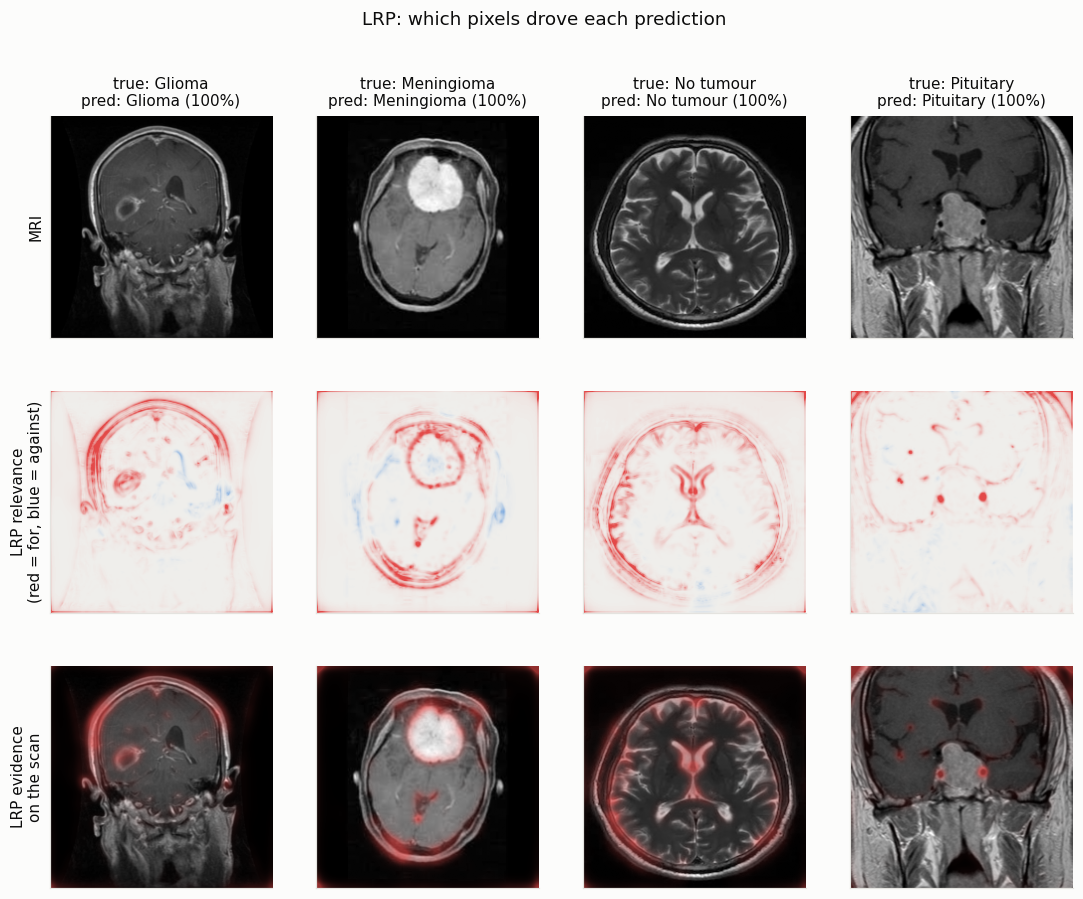

In [18]:
fig, axes = plt.subplots(3, len(correct_examples), figsize=(3 * len(correct_examples), 9.2))
axes = np.atleast_2d(axes).reshape(3, -1)
for j, r in enumerate(correct_examples):
    idx = per_image.loc[r, "index"]
    axes[0, j].imshow(gray_images[idx], cmap="gray"); axes[0, j].set_xticks([]); axes[0, j].set_yticks([])
    axes[0, j].set_title(title_for(r))
    show_lrp(axes[1, j], lrp_maps[idx])
    overlay(axes[2, j], gray_images[idx], lrp_for_overlay(lrp_maps[idx]), RED)
for ax, label in zip(axes[:, 0], ["MRI", "LRP relevance\n(red = for, blue = against)", "LRP evidence\non the scan"]):
    ax.set_ylabel(label, color=INK)
fig.suptitle("LRP: which pixels drove each prediction")
save(fig, "05_lrp_per_class.png")

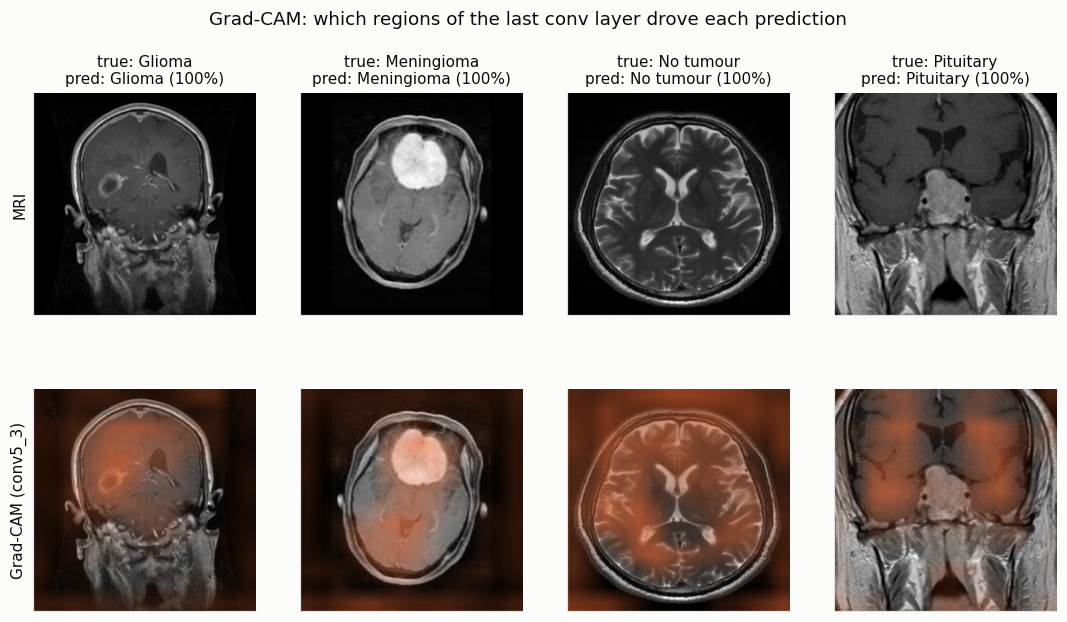

In [19]:
fig, axes = plt.subplots(2, len(correct_examples), figsize=(3 * len(correct_examples), 6.4))
axes = np.atleast_2d(axes).reshape(2, -1)
for j, r in enumerate(correct_examples):
    idx = per_image.loc[r, "index"]
    axes[0, j].imshow(gray_images[idx], cmap="gray"); axes[0, j].set_xticks([]); axes[0, j].set_yticks([])
    axes[0, j].set_title(title_for(r))
    overlay(axes[1, j], gray_images[idx], cam_maps[idx], ORANGE)
axes[0, 0].set_ylabel("MRI", color=INK)
axes[1, 0].set_ylabel("Grad-CAM (conv5_3)", color=INK)
fig.suptitle("Grad-CAM: which regions of the last conv layer drove each prediction")
save(fig, "06_gradcam_per_class.png")

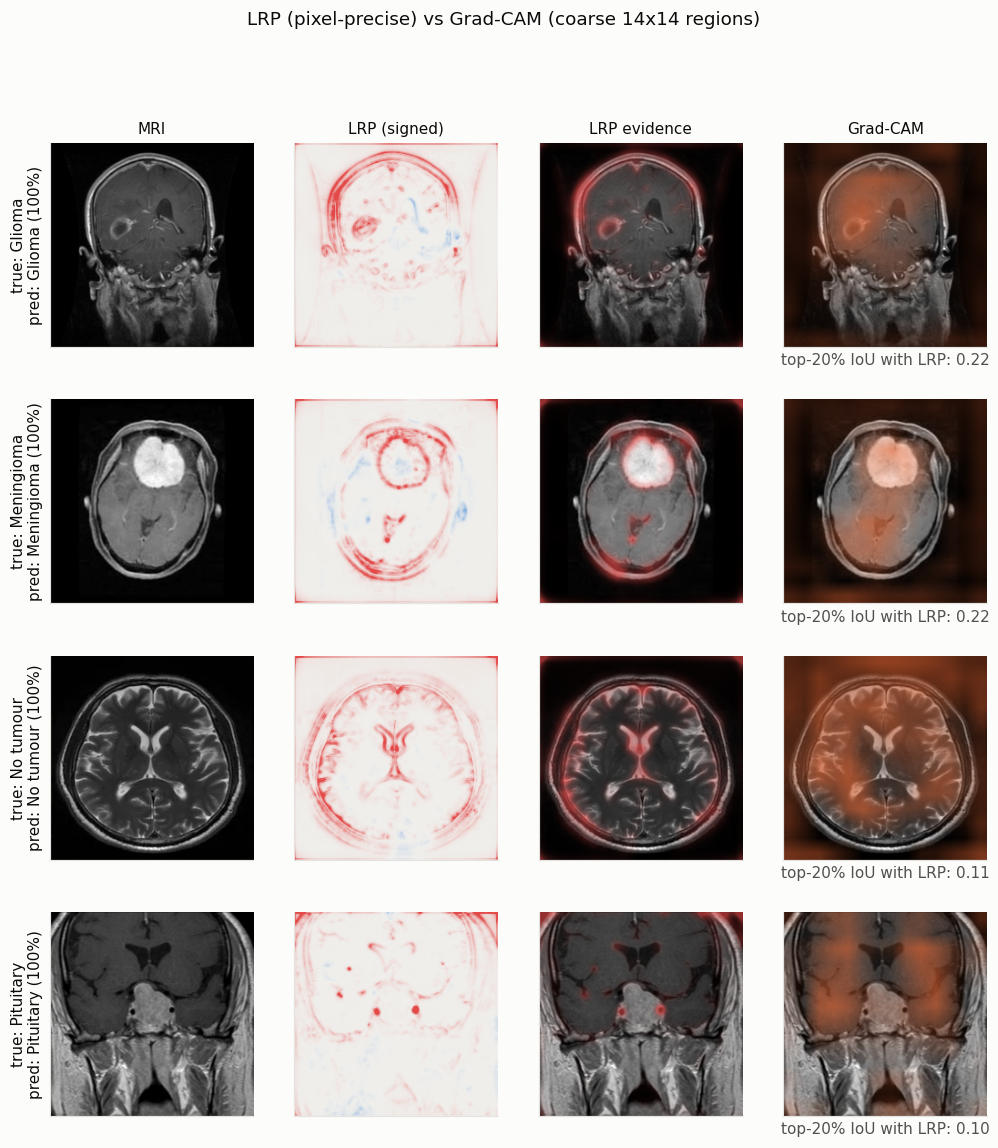

In [20]:
fig, axes = plt.subplots(len(correct_examples), 4, figsize=(11, 2.9 * len(correct_examples)))
axes = np.atleast_2d(axes)
for i, r in enumerate(correct_examples):
    row = per_image.loc[r]
    idx = row["index"]
    axes[i, 0].imshow(gray_images[idx], cmap="gray"); axes[i, 0].set_ylabel(title_for(r), color=INK)
    show_lrp(axes[i, 1], lrp_maps[idx])
    overlay(axes[i, 2], gray_images[idx], lrp_for_overlay(lrp_maps[idx]), RED)
    overlay(axes[i, 3], gray_images[idx], cam_maps[idx], ORANGE)
    axes[i, 3].set_xlabel(f"top-20% IoU with LRP: {row.top20_iou:.2f}", color=INK_2)
    for ax in axes[i]:
        ax.set_xticks([]); ax.set_yticks([])
for ax, t in zip(axes[0], ["MRI", "LRP (signed)", "LRP evidence", "Grad-CAM"]):
    ax.set_title(t)
fig.suptitle("LRP (pixel-precise) vs Grad-CAM (coarse 14x14 regions)")
save(fig, "07_lrp_vs_gradcam.png")

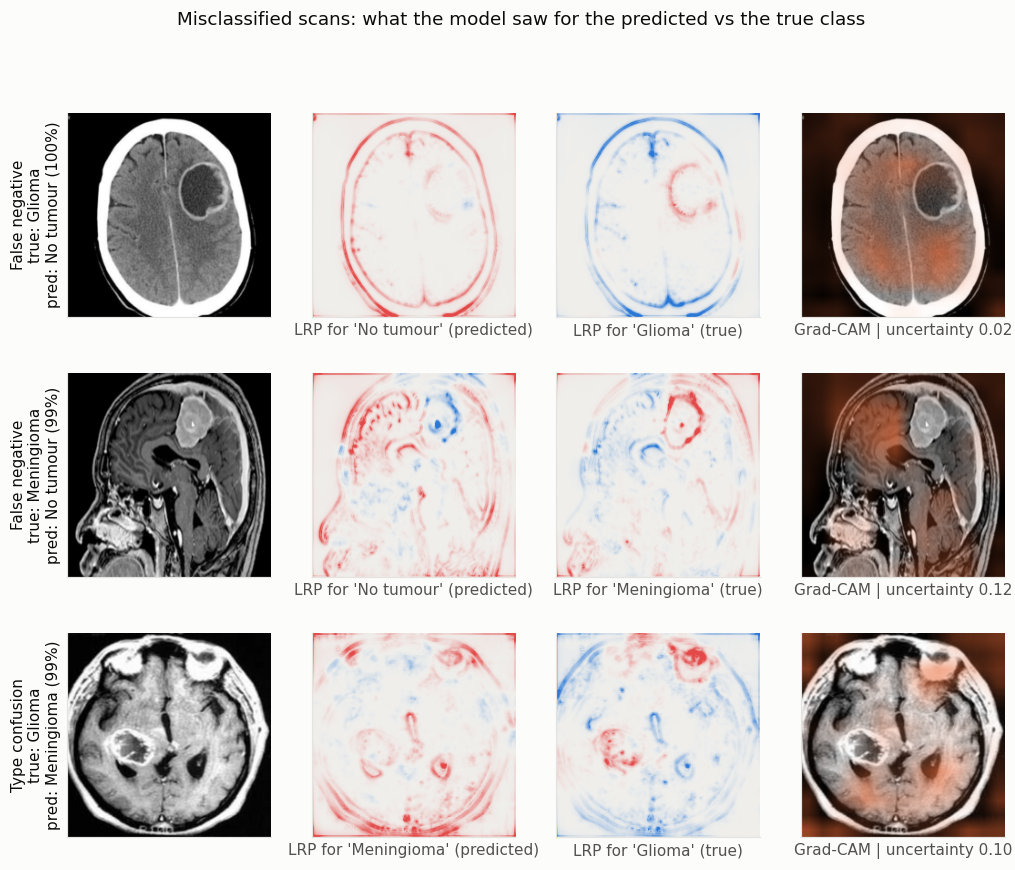

In [21]:
error_cases = ([("False negative", r) for r in false_negatives] +
               [("False positive", r) for r in false_positives] +
               [("Type confusion", r) for r in confusions])
if error_cases:
    fig, axes = plt.subplots(len(error_cases), 4, figsize=(11, 2.9 * len(error_cases)))
    axes = np.atleast_2d(axes)
    for i, (kind, r) in enumerate(error_cases):
        row = per_image.loc[r]
        idx = row["index"]
        image, label = test_dataset[idx]
        relevance_true, _, _ = apply_lrp_on_vgg16(image, target=label)
        axes[i, 0].imshow(gray_images[idx], cmap="gray")
        axes[i, 0].set_ylabel(f"{kind}\n{title_for(r)}", color=INK)
        show_lrp(axes[i, 1], lrp_maps[idx]); axes[i, 1].set_xlabel(f"LRP for '{row.pred}' (predicted)")
        show_lrp(axes[i, 2], relevance_true); axes[i, 2].set_xlabel(f"LRP for '{row.true}' (true)")
        overlay(axes[i, 3], gray_images[idx], cam_maps[idx], ORANGE)
        axes[i, 3].set_xlabel(f"Grad-CAM | uncertainty {row.entropy:.2f}")
        for ax in axes[i]:
            ax.set_xticks([]); ax.set_yticks([])
    fig.suptitle("Misclassified scans: what the model saw for the predicted vs the true class")
    save(fig, "08_error_analysis.png")

In [22]:
# Remove (set to black) the 16x16 patches an explanation ranks most important, in order,
# and watch the predicted-class probability. A faithful explanation makes it drop fast,
# i.e. gives a LOW area under the deletion curve (AUC). Random order is the baseline.
DELETE_FRACTIONS = np.array([0, .02, .05, .10, .15, .20, .30, .50, .75, 1.0])
BLACK = ((0 - torch.tensor(IMAGENET_MEAN)) / torch.tensor(IMAGENET_STD)).view(3, 1, 1)
rng = np.random.default_rng(SEED)


@torch.no_grad()
def deletion_curve(image, target, cell_scores):
    order = np.argsort(-cell_scores.ravel())
    batch = []
    for f in DELETE_FRACTIONS:
        keep = np.ones(196, dtype=np.float32)
        keep[order[:int(round(f * 196))]] = 0
        keep = torch.from_numpy(keep).view(1, 1, 14, 14)
        keep = F.interpolate(keep, size=(IMG_SIZE, IMG_SIZE), mode="nearest")[0]
        batch.append(image * keep + BLACK * (1 - keep))
    return F.softmax(model(torch.stack(batch).to(device)), 1)[:, target].cpu().numpy()


per_class = 3 if QUICK else 20
deletion_subset = per_image.groupby("true").head(per_class).index
curves = {"LRP": [], "Grad-CAM": [], "Random": []}
t0 = time.time()
for r in deletion_subset:
    idx = per_image.loc[r, "index"]
    image, _ = test_dataset[idx]
    target = NAMES.index(per_image.loc[r, "pred"])
    curves["LRP"].append(deletion_curve(image, target, pool_to_grid(np.clip(lrp_maps[idx], 0, None))))
    curves["Grad-CAM"].append(deletion_curve(image, target, pool_to_grid(cam_maps[idx])))
    curves["Random"].append(deletion_curve(image, target, rng.random((14, 14))))
print(f"Deletion test on {len(deletion_subset)} images in {time.time()-t0:.0f}s")
trapezoid = getattr(np, "trapezoid", None) or np.trapz  # np.trapz was renamed in NumPy 2.0
deletion_auc = {m: float(trapezoid(np.mean(c, 0), DELETE_FRACTIONS)) for m, c in curves.items()}
print("Deletion AUC (lower = more faithful):", {k: round(v, 3) for k, v in deletion_auc.items()})

Deletion test on 80 images in 21s
Deletion AUC (lower = more faithful): {'LRP': 0.378, 'Grad-CAM': 0.391, 'Random': 0.453}


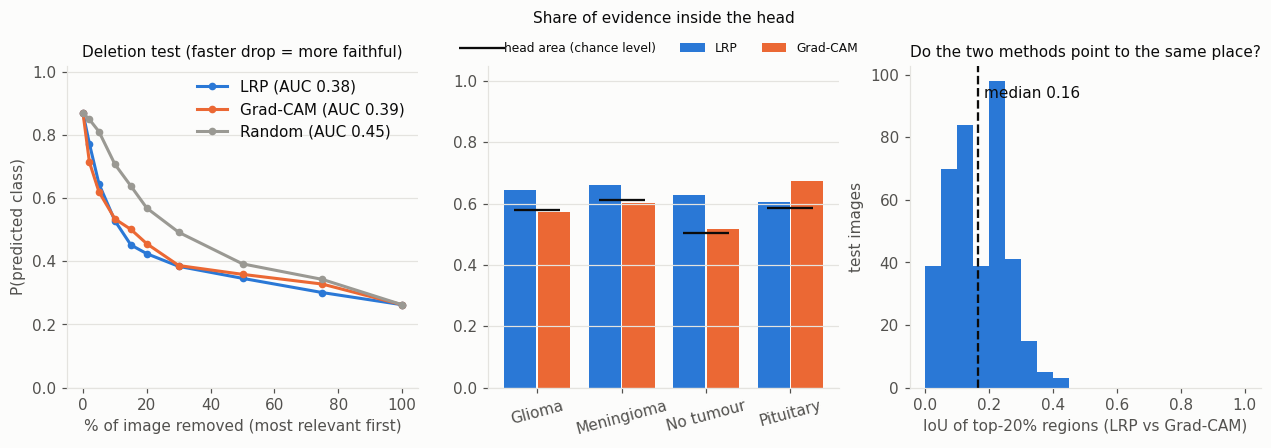

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
method_colors = {"LRP": BLUE, "Grad-CAM": ORANGE, "Random": GRAY}
for m, c in curves.items():
    axes[0].plot(DELETE_FRACTIONS * 100, np.mean(c, 0), color=method_colors[m], lw=2, marker="o", ms=4,
                 label=f"{m} (AUC {deletion_auc[m]:.2f})")
axes[0].set_xlabel("% of image removed (most relevant first)"); axes[0].set_ylabel("P(predicted class)")
axes[0].set_title("Deletion test (faster drop = more faithful)"); axes[0].legend(frameon=False); axes[0].grid(axis="y")
axes[0].set_ylim(0, 1.02)

positions = np.arange(4)
lrp_in = [per_image.loc[per_image.true == n, "lrp_in_head"] for n in NAMES]
cam_in = [per_image.loc[per_image.true == n, "cam_in_head"] for n in NAMES]
area = [per_image.loc[per_image.true == n, "head_area"].mean() for n in NAMES]
axes[1].bar(positions - 0.2, [s.mean() for s in lrp_in], width=0.38, color=BLUE, label="LRP")
axes[1].bar(positions + 0.2, [s.mean() for s in cam_in], width=0.38, color=ORANGE, label="Grad-CAM")
axes[1].scatter(positions, area, color=INK, marker="_", s=900, zorder=3, label="head area (chance level)")
axes[1].set_xticks(positions, NAMES, rotation=15); axes[1].set_ylim(0, 1.05)
axes[1].set_title("Share of evidence inside the head", pad=28)
axes[1].legend(frameon=False, fontsize=8, ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.0))
axes[1].grid(axis="y")

axes[2].hist(per_image.top20_iou, bins=np.linspace(0, 1, 21), color=BLUE)
axes[2].axvline(per_image.top20_iou.median(), color=INK, lw=1.5, ls="--")
axes[2].text(per_image.top20_iou.median() + 0.02, axes[2].get_ylim()[1] * 0.9,
             f"median {per_image.top20_iou.median():.2f}", color=INK)
axes[2].set_xlabel("IoU of top-20% regions (LRP vs Grad-CAM)"); axes[2].set_ylabel("test images")
axes[2].set_title("Do the two methods point to the same place?")
save(fig, "09_explanation_metrics.png")

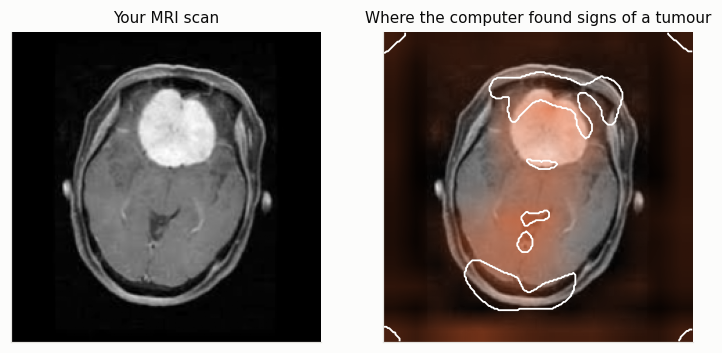

In [24]:
if correct_examples:
    tumour_examples = [r for r in correct_examples if per_image.loc[r, "true"] != "No tumour"]
    r = next((x for x in tumour_examples if per_image.loc[x, "true"] == "Meningioma"), tumour_examples[0])
    idx = per_image.loc[r, "index"]
    fig, axes = plt.subplots(1, 2, figsize=(8, 4.2))
    axes[0].imshow(gray_images[idx], cmap="gray"); axes[0].set_title("Your MRI scan")
    overlay(axes[1], gray_images[idx], cam_maps[idx], ORANGE, alpha_max=0.7)
    contour = (cv2.GaussianBlur(lrp_for_overlay(lrp_maps[idx]), (0, 0), 4) > 0.35).astype(np.uint8)
    axes[1].contour(contour, levels=[0.5], colors="white", linewidths=1.2)
    axes[1].set_title("Where the computer found signs of a tumour")
    for ax in axes:
        ax.set_xticks([]); ax.set_yticks([])
    save(fig, "10_patient_view.png")
    patient_case = per_image.loc[r].to_dict()
else:
    patient_case = {}

In [25]:
summary = {
    "test_accuracy": test_acc,
    "n_test": int(len(y_true)),
    "per_class": {n: {k: round(v, 3) for k, v in report[n].items()} for n in NAMES},
    "macro_f1": report["macro avg"]["f1-score"],
    "tumour_sensitivity": tumor_sensitivity,
    "tumour_specificity": tumor_specificity,
    "confusion_matrix": cm.tolist(),
    "class_order": NAMES,
    "ece": ece,
    "entropy_correct_mean": float(predictive_entropy[correct].mean()),
    "entropy_wrong_mean": float(predictive_entropy[~correct].mean()) if (~correct).any() else None,
    "selective_accuracy": dict(zip([round(c, 2) for c in coverages], selective_acc)),
    "best_val_acc": max(h["val_acc"] for h in history),
    "lrp_conservation_median": float(per_image.lrp_conservation.median()),
    "lrp_nonfinite_maps": int(n_bad_maps),
    "lrp_in_head_mean": float(per_image.lrp_in_head.mean()),
    "cam_in_head_mean": float(per_image.cam_in_head.mean()),
    "head_area_mean": float(per_image.head_area.mean()),
    "in_head_by_class": per_image.groupby("true")[["lrp_in_head", "cam_in_head", "head_area"]].mean().round(3).to_dict(),
    "top20_iou_median": float(per_image.top20_iou.median()),
    "rank_corr_median": float(per_image.rank_corr.median()),
    "deletion_auc": deletion_auc,
    "deletion_n_images": int(len(deletion_subset)),
    "examples": {
        "correct": per_image.loc[correct_examples].to_dict("records"),
        "false_negatives": per_image.loc[false_negatives].to_dict("records"),
        "false_positives": per_image.loc[false_positives].to_dict("records"),
        "confusions": per_image.loc[confusions].to_dict("records"),
        "patient_case": patient_case,
    },
}
(RESULTS_DIR / "summary.json").write_text(json.dumps(summary, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o)))
print(json.dumps({k: v for k, v in summary.items() if k != "examples"}, indent=2, default=str))

{
  "test_accuracy": 0.751269035532995,
  "n_test": 394,
  "per_class": {
    "Glioma": {
      "precision": 1.0,
      "recall": 0.31,
      "f1-score": 0.473,
      "support": 100.0
    },
    "Meningioma": {
      "precision": 0.66,
      "recall": 0.913,
      "f1-score": 0.766,
      "support": 115.0
    },
    "No tumour": {
      "precision": 0.705,
      "recall": 1.0,
      "f1-score": 0.827,
      "support": 105.0
    },
    "Pituitary": {
      "precision": 1.0,
      "recall": 0.743,
      "f1-score": 0.853,
      "support": 74.0
    }
  },
  "macro_f1": 0.7297976580625514,
  "tumour_sensitivity": 0.8477508650519031,
  "tumour_specificity": 1.0,
  "confusion_matrix": [
    [
      31,
      42,
      27,
      0
    ],
    [
      0,
      105,
      10,
      0
    ],
    [
      0,
      0,
      105,
      0
    ],
    [
      0,
      12,
      7,
      55
    ]
  ],
  "class_order": [
    "Glioma",
    "Meningioma",
    "No tumour",
    "Pituitary"
  ],
  "ece": 0.1471

In [26]:
# Set INCLUDE_WEIGHTS = True to also download the trained model (~530 MB, slow).
INCLUDE_WEIGHTS = True
if IN_COLAB:
    staging = Path("/content/brain_xai_outputs")
    shutil.rmtree(staging, ignore_errors=True)
    shutil.copytree(FIG_DIR, staging / "figures")
    shutil.copytree(RESULTS_DIR, staging / "results")
    if INCLUDE_WEIGHTS:
        (staging / "models").mkdir()
        shutil.copy(MODEL_PATH, staging / "models" / MODEL_PATH.name)
    archive = shutil.make_archive("/content/brain_xai_outputs", "zip", staging)
    print("Created", archive)
    from google.colab import files
    files.download(archive)

Created /content/brain_xai_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>